# Task 1 - Stock Market Prediction System

```
Sqrock IT Solutions - Data Science Internship - Phase 2

Predicts the next trading day's closing price for ten large US stocks from real
Yahoo Finance history (2015 -> today).

Method, and why
  * Every model predicts tomorrow's RETURN; the price forecast is close * exp(return).
    Tree models cannot output a price above anything seen in training, so predicting
    the price level directly breaks as soon as a stock makes a new high.
  * Strict time split, no shuffling: train < 2023, validation = 2023, test = 2024 -> today.
    Scalers are fitted on the training rows only.
  * A naive "tomorrow = today" baseline is scored next to every model. Daily prices are
    close to a random walk, so a high R2 on price alone proves nothing; beating the
    baseline is the real test.
  * Models: Linear Regression, Decision Tree, Random Forest, XGBoost (GPU) and one
    LSTM (PyTorch, GPU, mixed precision) trained jointly on all ten stocks.

Run:  python task1_stock_prediction/train.py          (about 2-3 minutes with a GPU)
```

In [1]:
import os, time
from IPython.display import Image, display
__file__ = os.path.abspath("train.py")   # run from the task folder so the script's relative paths resolve
_seen = time.time()

def show_new_figures(folder=os.path.join("artifacts", "figures")):
    """Display the charts saved since the previous cell."""
    global _seen
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder), key=lambda f: os.path.getmtime(os.path.join(folder, f))):
            p = os.path.join(folder, f)
            if f.endswith(".png") and os.path.getmtime(p) >= _seen:
                display(Image(p))
    _seen = time.time()

In [2]:
from __future__ import annotations

import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from limits import N_JOBS, limit_torch          # caps CPU threads and lowers process priority; must come before numpy

import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

from features import FEATURES, MARKET, TARGET, add_features, build, load_prices, tickers

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
limit_torch()                      # CPU threads + at most 90% of GPU memory

HERE = Path(__file__).resolve().parent
ART = HERE / "artifacts"
for sub in ("predictions", "forecast", "models", "figures"):
    (ART / sub).mkdir(parents=True, exist_ok=True)

VAL_START, TEST_START = "2023-01-01", "2024-01-01"
SEQ_LEN = 60           # LSTM looks at the last 60 trading days
HORIZON = 30           # forward forecast length (trading days)
COST = 0.0005          # 5 basis points per trade in the signal backtest
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAMES = ["Linear Regression", "Decision Tree", "Random Forest", "XGBoost", "LSTM"]

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def log(msg: str) -> None:
    print(msg, flush=True)


def price_metrics(actual, pred, prev_close) -> dict:
    """Error of a next-day price forecast, plus how often the direction was right."""
    actual, pred, prev_close = map(np.asarray, (actual, pred, prev_close))
    mse = mean_squared_error(actual, pred)
    return {
        "MAE": round(float(mean_absolute_error(actual, pred)), 4),
        "MSE": round(float(mse), 4),
        "RMSE": round(float(np.sqrt(mse)), 4),
        "R2": round(float(r2_score(actual, pred)), 5),
        "MAPE_pct": round(float(np.mean(np.abs(actual / pred - 1)) * 100), 3),
        "Direction_acc_pct": round(float(np.mean(np.sign(pred - prev_close) == np.sign(actual - prev_close)) * 100), 2),
    }

## 1. Data

In [3]:
log(f"STEP 1 - Data collection & cleaning   (device: {DEVICE}"
    + (f", {torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ")"))
NAMES = tickers()
SYMBOLS = [s for s in NAMES if s != MARKET]
frames, cleaning = {}, {}
for sym in SYMBOLS:
    frames[sym], cleaning[sym] = build(sym)
    r = cleaning[sym]
    log(f"  {sym:5s} {r['rows_clean']:5d} days | duplicates {r['duplicates']} | "
        f"missing {r['missing_values']} | invalid {r['invalid_prices']}")


def split(df: pd.DataFrame):
    d = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
    tr = d[d["Date"] < VAL_START]
    va = d[(d["Date"] >= VAL_START) & (d["Date"] < TEST_START)]
    te = d[d["Date"] >= TEST_START]
    return d, tr, va, te

STEP 1 - Data collection & cleaning   (device: cuda, NVIDIA GeForce GTX 1080)


  AAPL   2985 days | duplicates 0 | missing 0 | invalid 0


  MSFT   2985 days | duplicates 0 | missing 0 | invalid 0


  GOOGL  2985 days | duplicates 0 | missing 0 | invalid 0


  AMZN   2985 days | duplicates 0 | missing 0 | invalid 0


  NVDA   2985 days | duplicates 0 | missing 0 | invalid 0

  TSLA   2985 days | duplicates 0 | missing 0 | invalid 0


  META   2985 days | duplicates 0 | missing 0 | invalid 0

  JPM    2985 days | duplicates 0 | missing 0 | invalid 0

  JNJ    2985 days | duplicates 0 | missing 0 | invalid 0


  XOM    2985 days | duplicates 0 | missing 0 | invalid 0


## 2. Eda Figures

STEP 2 - Exploratory analysis figures


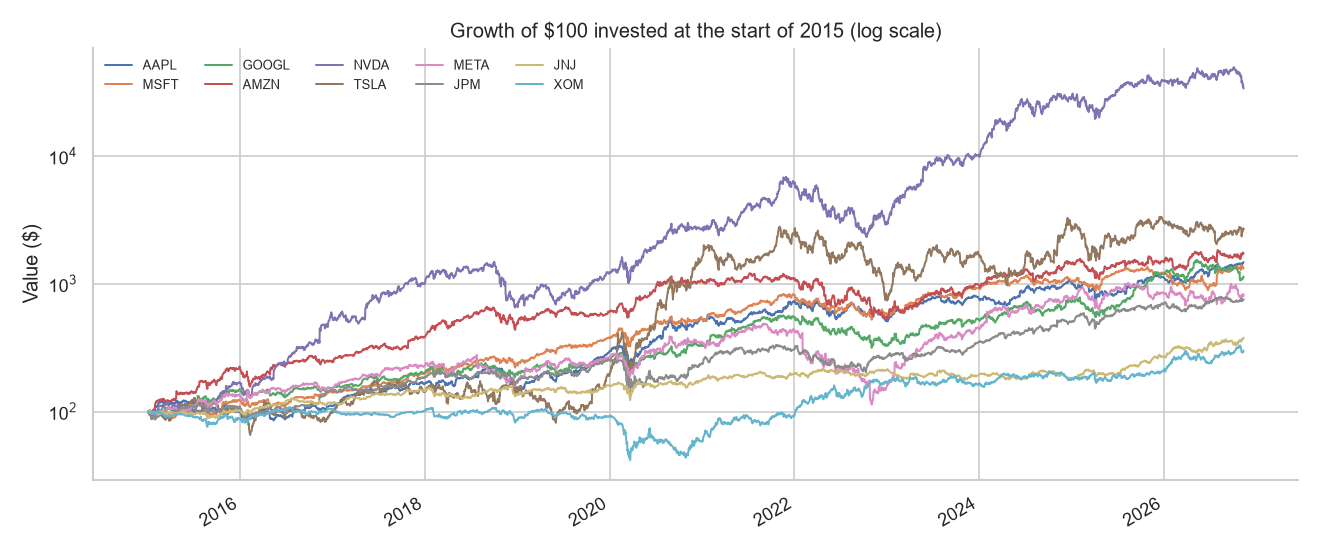

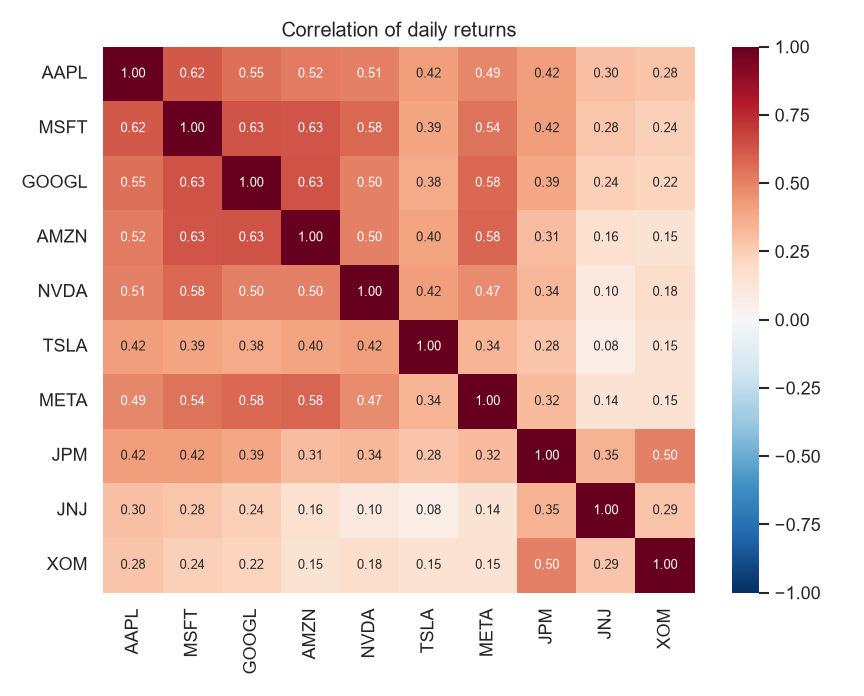

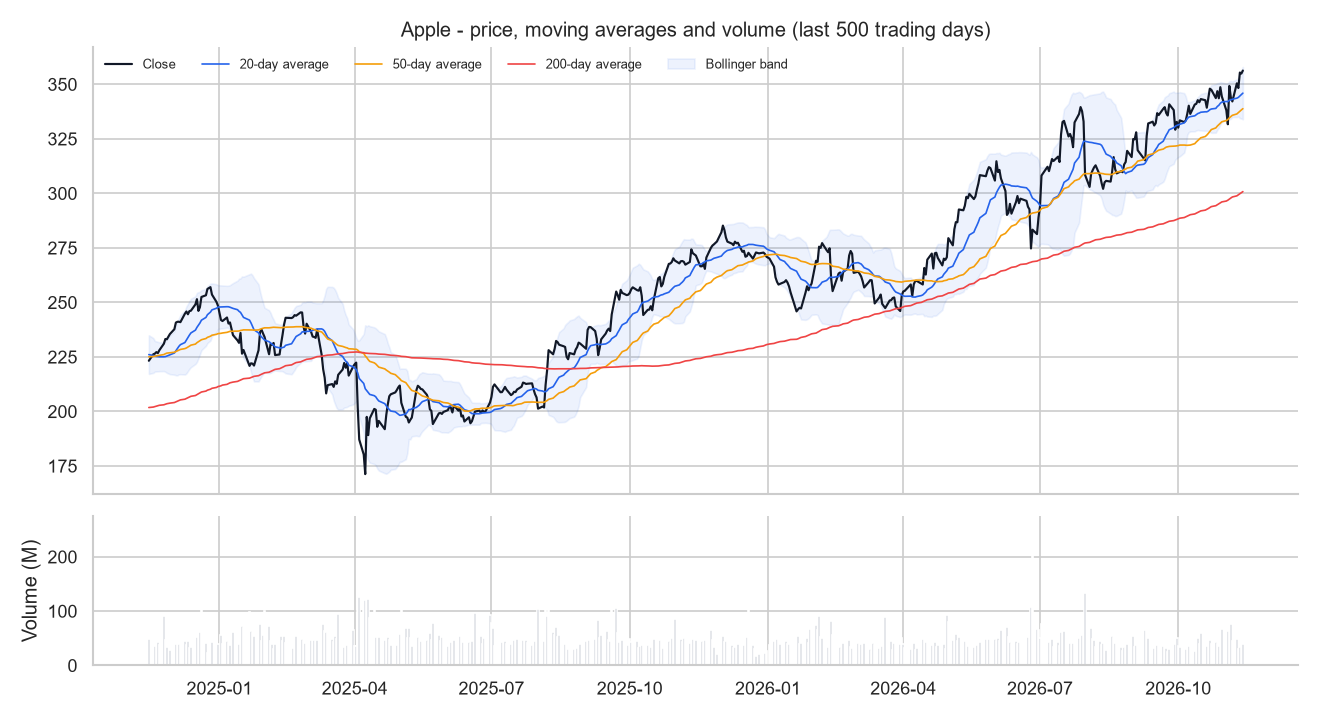

In [4]:
log("STEP 2 - Exploratory analysis figures")
closes = pd.DataFrame({s: frames[s].set_index("Date")["Close"] for s in SYMBOLS}).dropna()
rets = np.log(closes).diff().dropna()

fig, ax = plt.subplots(figsize=(11, 4.6))
(closes / closes.iloc[0] * 100).plot(ax=ax, lw=1.2)
ax.set_yscale("log"); ax.set_title("Growth of $100 invested at the start of 2015 (log scale)")
ax.set_xlabel(""); ax.set_ylabel("Value ($)"); ax.legend(ncol=5, fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(ART / "figures" / "eda_growth.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.2, 5.8))
sns.heatmap(rets.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation of daily returns")
fig.tight_layout(); fig.savefig(ART / "figures" / "eda_correlation.png"); plt.close(fig)

d = frames["AAPL"].tail(500)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(d["Date"], d["Close"], color="#111827", lw=1.3, label="Close")
for n, col in ((20, "#2563eb"), (50, "#f59e0b"), (200, "#ef4444")):
    axes[0].plot(d["Date"], d[f"sma_{n}"], lw=1, color=col, label=f"{n}-day average")
axes[0].fill_between(d["Date"], d["boll_lo"], d["boll_up"], color="#2563eb", alpha=0.08, label="Bollinger band")
axes[0].set_title("Apple - price, moving averages and volume (last 500 trading days)")
axes[0].legend(ncol=5, fontsize=8, frameon=False)
axes[1].bar(d["Date"], d["Volume"] / 1e6, color="#64748b", width=1.0)
axes[1].set_ylabel("Volume (M)")
fig.tight_layout(); fig.savefig(ART / "figures" / "eda_price_ma_volume.png"); plt.close(fig)
show_new_figures()

## 3. Classical Models

In [5]:
log("STEP 3 - Linear Regression / Decision Tree / Random Forest / XGBoost (per stock)")


def make_xgb(device: str) -> xgb.XGBRegressor:
    return xgb.XGBRegressor(
        n_estimators=600, learning_rate=0.02, max_depth=3, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=5.0, tree_method="hist", n_jobs=N_JOBS,
        device=device, early_stopping_rounds=50, random_state=SEED, verbosity=0)


XGB_DEVICE = DEVICE
store, bundles = {}, {}
t0 = time.time()
for sym in SYMBOLS:
    d, tr, va, te = split(frames[sym])
    scaler = StandardScaler().fit(tr[FEATURES])          # normalisation: training rows only
    Xtr, Xva, Xte = (scaler.transform(p[FEATURES]) for p in (tr, va, te))
    ytr, yva = tr[TARGET].values, va[TARGET].values

    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=60, random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=30,
                                               max_features=0.5, n_jobs=N_JOBS, random_state=SEED),
    }
    for m in models.values():
        m.fit(Xtr, ytr)
    try:
        bst = make_xgb(XGB_DEVICE).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    except Exception as exc:                              # GPU build / driver not usable
        log(f"  XGBoost GPU unavailable ({str(exc)[:60]}...), using CPU")
        XGB_DEVICE = "cpu"
        bst = make_xgb("cpu").fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    bst.set_params(device="cpu")                          # predict from numpy without a device warning
    models["XGBoost"] = bst

    store[sym] = {"d": d, "tr": tr, "va": va, "te": te, "scaler": scaler,
                  "ret_pred": {n: {"va": m.predict(Xva), "te": m.predict(Xte)} for n, m in models.items()}}
    bundles[sym] = {"scaler": scaler, "features": FEATURES, **models}
log(f"  trained 4 models x {len(SYMBOLS)} stocks in {time.time() - t0:.1f}s (XGBoost on {XGB_DEVICE})")

STEP 3 - Linear Regression / Decision Tree / Random Forest / XGBoost (per stock)


  trained 4 models x 10 stocks in 8.3s (XGBoost on cuda)


## 4. Lstm (Gpu)

STEP 4 - LSTM neural network on cuda (one model for all stocks)


  training windows 17,560 | validation windows 2,500 | shape (60, 30)


  epoch  5  train 1.6493  val 1.4945


  epoch  9  train 1.6193  val 1.4959


  early stop (no validation gain for 8 epochs)


  LSTM trained in 3.6s, best validation loss 1.4924


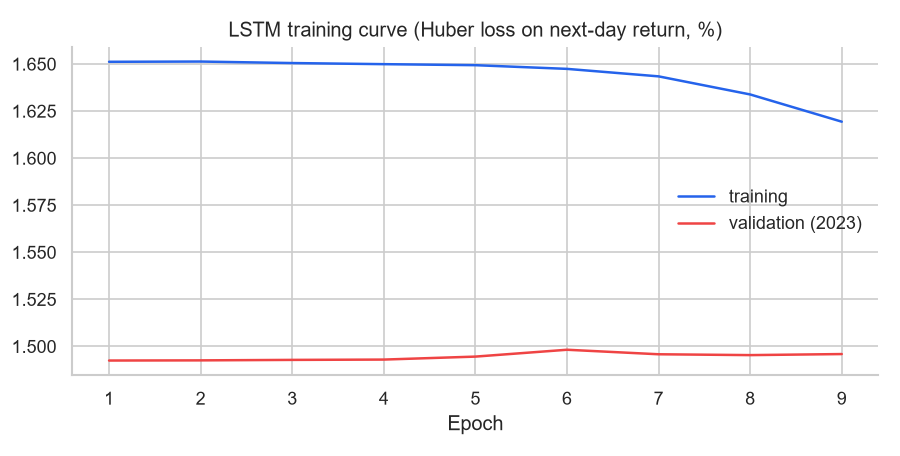

In [6]:
log(f"STEP 4 - LSTM neural network on {DEVICE} (one model for all stocks)")


def sequences(sym: str, part: str):
    """60-day windows of scaled features ending on each row of the requested split."""
    s = store[sym]
    X = s["scaler"].transform(s["d"][FEATURES]).astype(np.float32)
    idx = s[part].index.values
    idx = idx[idx >= SEQ_LEN - 1]
    win = np.stack([X[i - SEQ_LEN + 1: i + 1] for i in idx])
    y = s["d"].loc[idx, TARGET].values.astype(np.float32) * 100   # in percent: better conditioned
    return win, y, np.full(len(idx), SYMBOLS.index(sym)), idx


class PriceLSTM(nn.Module):
    def __init__(self, n_feat: int, n_sym: int, hidden: int = 64):
        super().__init__()
        self.emb = nn.Embedding(n_sym, 4)                 # lets one network specialise per stock
        self.lstm = nn.LSTM(n_feat + 4, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 1))

    def forward(self, x, sym):
        e = self.emb(sym).unsqueeze(1).expand(-1, x.size(1), -1)
        out, _ = self.lstm(torch.cat([x, e], dim=2))
        return self.head(out[:, -1]).squeeze(-1)


def stack(part: str):
    parts = [sequences(s, part) for s in SYMBOLS]
    return [np.concatenate([p[i] for p in parts]) for i in range(3)]


Xtr, ytr, str_ = stack("tr")
Xva, yva, sva = stack("va")
to = lambda a, dt=torch.float32: torch.as_tensor(a, dtype=dt, device=DEVICE)
Xtr_t, ytr_t, str_t = to(Xtr), to(ytr), to(str_, torch.long)
Xva_t, yva_t, sva_t = to(Xva), to(yva), to(sva, torch.long)
log(f"  training windows {len(Xtr):,} | validation windows {len(Xva):,} | shape {Xtr.shape[1:]}")

net = PriceLSTM(len(FEATURES), len(SYMBOLS)).to(DEVICE)
opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-3)
EPOCHS, BATCH, PATIENCE = 40, 512, 8
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=EPOCHS * (len(Xtr) // BATCH + 1))
loss_fn = nn.HuberLoss(delta=2.0)
use_amp = DEVICE == "cuda"
scaler_amp = torch.amp.GradScaler(enabled=use_amp)
history, best_val, best_state, bad = [], float("inf"), None, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    net.train()
    perm = torch.randperm(len(Xtr_t), device=DEVICE)
    total = 0.0
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=use_amp):
            loss = loss_fn(net(Xtr_t[b], str_t[b]), ytr_t[b])
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(opt)
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        scaler_amp.step(opt); scaler_amp.update(); sched.step()
        total += loss.item() * len(b)
    net.eval()
    with torch.no_grad(), torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=use_amp):
        val = loss_fn(net(Xva_t, sva_t).float(), yva_t).item()
    history.append({"epoch": epoch, "train_loss": round(total / len(perm), 5), "val_loss": round(val, 5)})
    if val < best_val - 1e-5:
        best_val, bad = val, 0
        best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
        bad += 1
    if epoch % 5 == 0 or bad == PATIENCE:
        log(f"  epoch {epoch:2d}  train {history[-1]['train_loss']:.4f}  val {val:.4f}")
    if bad == PATIENCE:
        log(f"  early stop (no validation gain for {PATIENCE} epochs)")
        break
net.load_state_dict(best_state)
net.eval()
lstm_seconds = time.time() - t0
log(f"  LSTM trained in {lstm_seconds:.1f}s, best validation loss {best_val:.4f}")
torch.save({"state": best_state, "features": FEATURES, "symbols": SYMBOLS, "seq_len": SEQ_LEN,
            "hidden": 64}, ART / "models" / "lstm.pt")


@torch.no_grad()
def lstm_predict(win: np.ndarray, sym: str) -> np.ndarray:
    s = torch.full((len(win),), SYMBOLS.index(sym), dtype=torch.long, device=DEVICE)
    return net(to(win), s).float().cpu().numpy() / 100


for sym in SYMBOLS:
    for part in ("va", "te"):
        win, _, _, idx = sequences(sym, part)
        full = pd.Series(0.0, index=store[sym][part].index)
        full.loc[idx] = lstm_predict(win, sym)
        store[sym]["ret_pred"].setdefault("LSTM", {})[part] = full.values

fig, ax = plt.subplots(figsize=(7.5, 3.8))
h = pd.DataFrame(history)
ax.plot(h["epoch"], h["train_loss"], label="training", color="#2563eb")
ax.plot(h["epoch"], h["val_loss"], label="validation (2023)", color="#ef4444")
ax.set_title("LSTM training curve (Huber loss on next-day return, %)"); ax.set_xlabel("Epoch"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(ART / "figures" / "lstm_training.png"); plt.close(fig)
show_new_figures()

## 5. Evaluation

In [7]:
log("STEP 5 - Evaluation on the unseen test period (2024 -> today)")
results = {}
for sym in SYMBOLS:
    s = store[sym]
    te, va = s["te"], s["va"]
    out = pd.DataFrame({"Date": s["d"]["Date"].shift(-1).loc[te.index].values,   # the day being predicted
                        "Prev_Close": te["Close"].values, "Actual": te["next_close"].values})
    out["Date"] = out["Date"].fillna(te["Date"].iloc[-1] + pd.tseries.offsets.BDay(1))
    m = {"Naive (tomorrow = today)": price_metrics(out["Actual"], out["Prev_Close"], out["Prev_Close"])}
    m["Naive (tomorrow = today)"]["Direction_acc_pct"] = None      # it predicts "no change", so it has no direction
    val_rmse = {}
    for name in MODEL_NAMES:
        out[name] = te["Close"].values * np.exp(s["ret_pred"][name]["te"])
        m[name] = price_metrics(out["Actual"], out[name], out["Prev_Close"])
        val_rmse[name] = float(np.sqrt(mean_squared_error(
            va["next_close"], va["Close"].values * np.exp(s["ret_pred"][name]["va"]))))
    best = min(val_rmse, key=val_rmse.get)               # chosen on validation, never on test

    # Signal backtest: hold the stock on days the chosen model expects a rise, else stay in cash.
    realised = np.log(out["Actual"] / out["Prev_Close"]).values
    position = (s["ret_pred"][best]["te"] > 0).astype(float)
    trades = np.abs(np.diff(np.concatenate([[0], position])))
    strat = position * realised - trades * COST
    out["Signal"] = np.where(position > 0, "BUY/HOLD", "SELL/CASH")
    backtest = {
        "strategy_return_pct": round(float((np.exp(strat.sum()) - 1) * 100), 2),
        "buy_and_hold_return_pct": round(float((np.exp(realised.sum()) - 1) * 100), 2),
        "days_in_market_pct": round(float(position.mean() * 100), 1),
        "trades": int(trades.sum()),
    }
    out.round(4).to_csv(ART / "predictions" / f"{sym}.csv", index=False)
    results[sym] = {"name": NAMES[sym], "cleaning": cleaning[sym],
                    "rows": {"train": len(s["tr"]), "validation": len(va), "test": len(te)},
                    "models": m, "best_model": best, "validation_rmse": {k: round(v, 4) for k, v in val_rmse.items()},
                    "backtest": backtest, "last_close": round(float(frames[sym]["Close"].iloc[-1]), 2),
                    "last_date": str(frames[sym]["Date"].iloc[-1].date())}
    b, nv = m[best], m["Naive (tomorrow = today)"]
    log(f"  {sym:5s} best={best:17s} RMSE {b['RMSE']:7.3f} (naive {nv['RMSE']:7.3f})  "
        f"R2 {b['R2']:.4f}  MAPE {b['MAPE_pct']:.2f}%  direction {b['Direction_acc_pct']:.1f}%")

# average skill of each model across the ten stocks, relative to the naive baseline
summary = {}
for name in ["Naive (tomorrow = today)"] + MODEL_NAMES:
    rm = [results[s]["models"][name]["RMSE"] / results[s]["models"]["Naive (tomorrow = today)"]["RMSE"] for s in SYMBOLS]
    summary[name] = {
        "rmse_vs_naive": round(float(np.mean(rm)), 4),
        "mean_R2": round(float(np.mean([results[s]["models"][name]["R2"] for s in SYMBOLS])), 5),
        "mean_MAPE_pct": round(float(np.mean([results[s]["models"][name]["MAPE_pct"] for s in SYMBOLS])), 3),
        "mean_direction_acc_pct": None if name.startswith("Naive") else round(float(np.mean(
            [results[s]["models"][name]["Direction_acc_pct"] for s in SYMBOLS])), 2),
        "stocks_beating_naive": int(sum(r < 1 for r in rm)),
    }
log("\n  MODEL SUMMARY (average over 10 stocks; rmse_vs_naive < 1 means better than the baseline)")
log(pd.DataFrame(summary).T.to_string())

STEP 5 - Evaluation on the unseen test period (2024 -> today)


  AAPL  best=LSTM              RMSE   4.071 (naive   4.076)  R2 0.9926  MAPE 1.17%  direction 53.9%


  MSFT  best=XGBoost           RMSE   7.280 (naive   7.265)  R2 0.9772  MAPE 1.15%  direction 51.8%


  GOOGL best=LSTM              RMSE   4.992 (naive   4.991)  R2 0.9961  MAPE 1.40%  direction 54.3%


  AMZN  best=LSTM              RMSE   4.414 (naive   4.413)  R2 0.9787  MAPE 1.47%  direction 51.7%


  NVDA  best=XGBoost           RMSE   4.283 (naive   4.277)  R2 0.9913  MAPE 2.20%  direction 53.2%


... (3 outputs left out)

  JNJ   best=XGBoost           RMSE   2.355 (naive   2.361)  R2 0.9973  MAPE 0.86%  direction 54.0%


  XOM   best=Random Forest     RMSE   1.923 (naive   1.921)  R2 0.9931  MAPE 1.13%  direction 50.7%



  MODEL SUMMARY (average over 10 stocks; rmse_vs_naive < 1 means better than the baseline)


                          rmse_vs_naive  mean_R2  mean_MAPE_pct  mean_direction_acc_pct  stocks_beating_naive
Naive (tomorrow = today)         1.0000  0.98816          1.479                     NaN                   0.0
Linear Regression                1.0177  0.98768          1.508                   49.96                   1.0
Decision Tree                    1.0127  0.98789          1.493                   51.64                   1.0
Random Forest                    1.0034  0.98803          1.482                   51.05                   2.0
XGBoost                          1.0002  0.98815          1.475                   52.51                   5.0
LSTM                             0.9996  0.98816          1.473                   53.22                   4.0

## 6. Forward Forecast

In [8]:
log(f"\nSTEP 6 - {HORIZON}-day forward forecast with each stock's best model")
market_prices, _ = load_prices(MARKET)
mkt_drift = float(np.log(market_prices["Close"]).diff().tail(250).mean())


def predict_return(sym: str, model: str, feats: pd.DataFrame) -> float:
    """Predicted next-day return from the latest feature rows."""
    X = store[sym]["scaler"].transform(feats[FEATURES].tail(SEQ_LEN)).astype(np.float32)
    if model == "LSTM":
        return float(lstm_predict(X[None], sym)[0])
    return float(bundles[sym][model].predict(X[-1:])[0])


for sym in SYMBOLS:
    best = results[sym]["best_model"]
    prices, _ = load_prices(sym)
    hist = prices.tail(320).reset_index(drop=True)
    mkt = market_prices.tail(320).reset_index(drop=True)
    rng = float((hist["High"] - hist["Low"]).div(hist["Close"]).tail(20).mean())
    vol = float(hist["Volume"].tail(20).mean())
    sigma = float(np.log(hist["Close"]).diff().tail(60).std())
    rows = []
    for h in range(1, HORIZON + 1):
        feats = add_features(hist, mkt)
        r = predict_return(sym, best, feats)
        last, day = hist.iloc[-1], hist["Date"].iloc[-1] + pd.tseries.offsets.BDay(1)
        close = float(last["Close"] * np.exp(r))
        # the simulated future day: typical range and volume, market drifting at its 1-year average
        hist = pd.concat([hist, pd.DataFrame([{"Date": day, "Open": last["Close"], "High": close * (1 + rng / 2),
                                               "Low": close * (1 - rng / 2), "Close": close, "Volume": vol}])],
                         ignore_index=True)
        mkt = pd.concat([mkt, pd.DataFrame([{"Date": day, "Open": 0, "High": 0, "Low": 0,
                                             "Close": float(mkt["Close"].iloc[-1] * np.exp(mkt_drift)), "Volume": 0}])],
                        ignore_index=True)
        band = 1.2816 * sigma * np.sqrt(h)                # 80% interval of a random walk with recent volatility
        rows.append({"Date": day, "Forecast": close, "Lower_80": close * np.exp(-band), "Upper_80": close * np.exp(band)})
    fc = pd.DataFrame(rows)
    fc.round(4).to_csv(ART / "forecast" / f"{sym}.csv", index=False)
    results[sym]["forecast"] = {
        "model": best, "next_day": round(float(fc["Forecast"].iloc[0]), 2),
        "day_30": round(float(fc["Forecast"].iloc[-1]), 2),
        "expected_change_30d_pct": round(float((fc["Forecast"].iloc[-1] / results[sym]["last_close"] - 1) * 100), 2),
        "signal": "BUY" if fc["Forecast"].iloc[0] > results[sym]["last_close"] else "SELL",
    }
    log(f"  {sym:5s} last {results[sym]['last_close']:9.2f} -> next day {fc['Forecast'].iloc[0]:9.2f} "
        f"| day 30 {fc['Forecast'].iloc[-1]:9.2f} ({results[sym]['forecast']['expected_change_30d_pct']:+.2f}%)")


STEP 6 - 30-day forward forecast with each stock's best model

  AAPL  last    356.27 -> next day    356.69 | day 30    369.15 (+3.62%)


  MSFT  last    523.88 -> next day    524.36 | day 30    538.45 (+2.78%)


  GOOGL last    295.77 -> next day    296.10 | day 30    305.86 (+3.41%)


  AMZN  last    266.66 -> next day    266.96 | day 30    276.13 (+3.55%)


  NVDA  last    162.85 -> next day    163.09 | day 30    170.78 (+4.87%)


  TSLA  last    390.22 -> next day    389.85 | day 30    375.05 (-3.89%)


  META  last    641.69 -> next day    642.47 | day 30    665.20 (+3.66%)


  JPM   last    346.19 -> next day    345.82 | day 30    359.72 (+3.91%)


  JNJ   last    285.75 -> next day    285.88 | day 30    289.54 (+1.33%)


  XOM   last    170.59 -> next day    170.59 | day 30    168.61 (-1.16%)


## 7. Figures + Save

STEP 7 - Saving models, metrics and report figures


TASK 1 COMPLETE


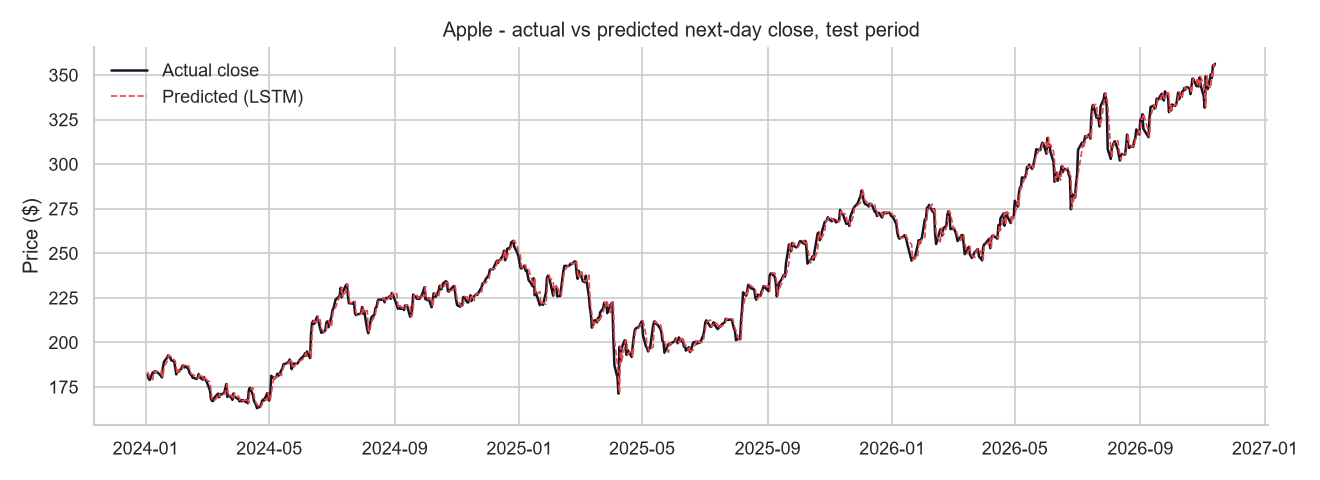

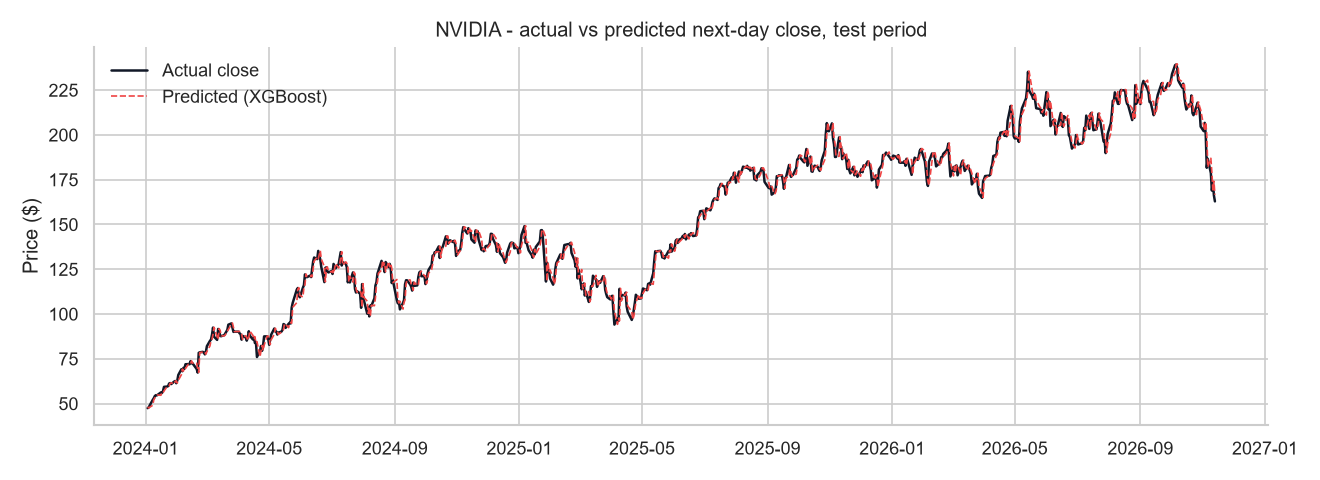

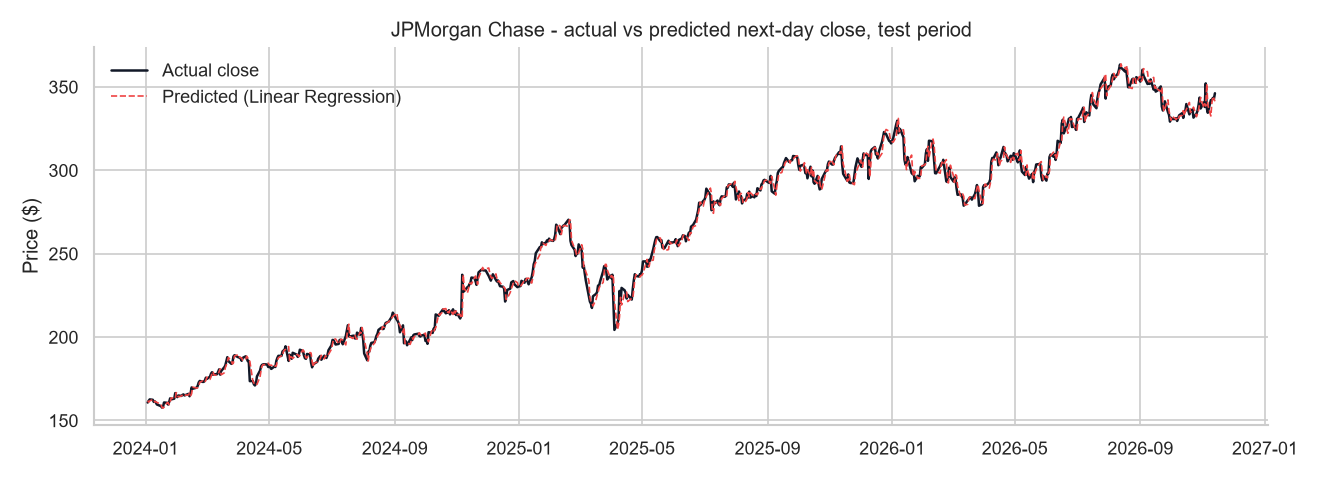

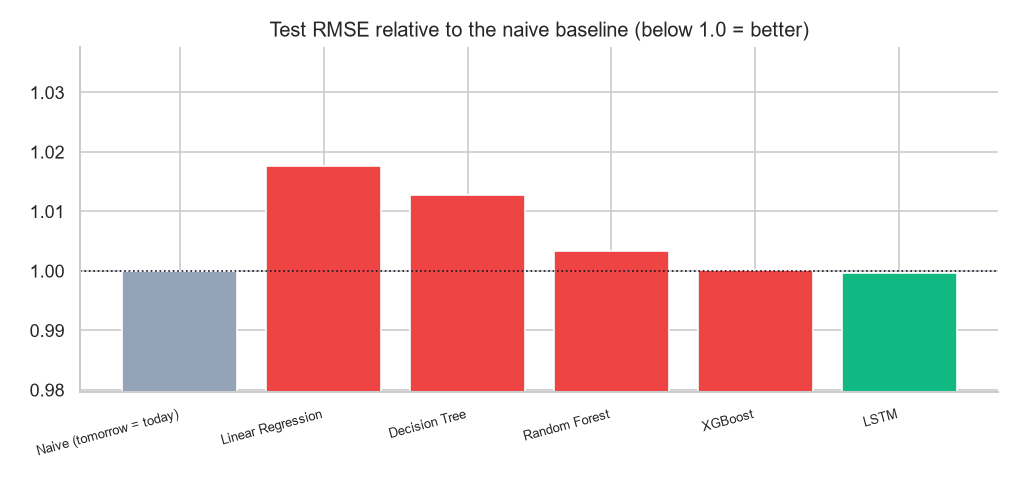

In [9]:
log("STEP 7 - Saving models, metrics and report figures")
for sym in SYMBOLS:
    joblib.dump(bundles[sym], ART / "models" / f"{sym}.joblib", compress=3)

for sym in ("AAPL", "NVDA", "JPM"):
    p = pd.read_csv(ART / "predictions" / f"{sym}.csv", parse_dates=["Date"])
    best = results[sym]["best_model"]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(p["Date"], p["Actual"], color="#111827", lw=1.5, label="Actual close")
    ax.plot(p["Date"], p[best], color="#ef4444", lw=1, ls="--", label=f"Predicted ({best})")
    ax.set_title(f"{NAMES[sym]} - actual vs predicted next-day close, test period")
    ax.legend(frameon=False); ax.set_ylabel("Price ($)")
    fig.tight_layout(); fig.savefig(ART / "figures" / f"actual_vs_predicted_{sym}.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 4))
sm = pd.DataFrame(summary).T
colors = ["#94a3b8"] + ["#10b981" if v < 1 else "#ef4444" for v in sm["rmse_vs_naive"].iloc[1:]]
ax.bar(sm.index, sm["rmse_vs_naive"], color=colors)
ax.axhline(1, color="#111827", lw=1, ls=":")
ax.set_ylim(sm["rmse_vs_naive"].min() - 0.02, sm["rmse_vs_naive"].max() + 0.02)
ax.set_title("Test RMSE relative to the naive baseline (below 1.0 = better)")
ax.set_xticklabels(sm.index, rotation=15, ha="right", fontsize=8)
fig.tight_layout(); fig.savefig(ART / "figures" / "model_comparison.png"); plt.close(fig)

metrics = {
    "task": "Stock Market Prediction System",
    "dataset": "Yahoo Finance daily OHLCV, split/dividend adjusted",
    "date_range": [str(closes.index.min().date()), str(max(f["Date"].max() for f in frames.values()).date())],
    "split": {"train": f"< {VAL_START}", "validation": f"{VAL_START} .. {TEST_START}", "test": f">= {TEST_START}"},
    "target": "next-day log return, converted to a next-day closing price",
    "features": FEATURES,
    "device": {"lstm": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu", "xgboost": XGB_DEVICE,
               "lstm_train_seconds": round(lstm_seconds, 1), "mixed_precision": use_amp},
    "lstm": {"sequence_length": SEQ_LEN, "architecture": "2-layer LSTM(64) + stock embedding + MLP head",
             "epochs_run": len(history), "history": history},
    "summary": summary,
    "tickers": results,
    "correlation": rets.corr().round(3).to_dict(),
}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
log("TASK 1 COMPLETE")
show_new_figures()